# Radial transfer: one outer supernova and an inner lens prior

We connect an outer SN brightness to an inner-profile summary through a stellar–halo–core family. The endpoint is $s_E=1-\kappa(\theta_E)$ at each state's own Einstein radius; it differs from the parameter of an exact mass-sheet transformation (MST).

With the environment in [the notebook guide](README.md), run from the repository root or `notebooks/` using Python 3.10+. This calculation usually takes a few seconds.

1. Build weighted mass states at a fixed SN image radius.
2. Condition on mock inner imaging, then add one SN brightness.
3. Average over brightness outcomes and vary the physical assumptions.

In [1]:
from pathlib import Path
import sys
import time

# Make the source tree importable from the root or notebooks directory.
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "ilsn" / "mass_grid.py").is_file()), None)
if root is not None and str(root) not in sys.path:
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.integrate import trapezoid
from ilsn.mass_grid import LensDesign, MassGrid, PhysicalRelations
from ilsn.lens_bank import build_lens_bank
from ilsn.observation import source_sample, imaging_log_likelihood
from ilsn.response import ResponseCalibration
from ilsn.likelihood import SourceLikelihood, SharedNuisance
from ilsn.radial import RadialTransfer

blue, orange = "#305f91", "#cf803e"
plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "dejavuserif",
                     "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
started = time.perf_counter()

%matplotlib inline

## 1. Declare the physical family

`LensDesign` assigns reference mass, light radius, redshifts, and the observed SN angle. The reference mass is a design covariate. `PhysicalRelations` supplies simulation relations for halo $M_{200}$ and concentration.

The 216 states vary stellar normalization, halo residual, stellar mass-to-light gradient, signed broad-core amplitude $\eta$, core radius $qR_e$, and zero-total-mass redistribution. Base weights use the library's finite-axis measures: the three $q$ values have equal discrete probabilities, and the other axes follow their declared densities.

In [2]:
design = LensDesign(
    log_design_mass=11.3, re_arcsec=0.9, z_lens=0.3, z_source=1.2,
    radius_arcsec=5.0,                       # fixed observed angle, arcsec
)
relations = PhysicalRelations()
grid = MassGrid(
    mass_multipliers=(0.8, 1.3), halo_nodes=(-1.0, 1.0),
    concentration_nodes=(0.0,), gradients=(-0.3, 0.0), halo_slopes=(1.0,),
    eta_nodes=(-0.1, 0.0, 0.1), q_nodes=(3.0, 5.0, 10.0),
    compensation_nodes=(-0.05, 0.0, 0.05),
)
bank = build_lens_bank(design, grid, relations, radial_nodes=129)
print(f"{len(grid)} states; fixed SN radius = {design.radius_arcsec[0]:.1f} arcsec")

216 states; fixed SN radius = 5.0 arcsec


In [3]:
mask_names = ("physical_valid", "geometry_valid", "projection_valid",
              "endpoint_valid", "single_image")
admitted = np.logical_and.reduce([bank[name][0] for name in mask_names])
for name in (*mask_names, "support_invalid", "support_unresolved"):
    print(f"{name:20s} {int(bank[name][0].sum()):3d} / {len(grid)}")
print(f"All required masks:   {admitted.sum():3d} / {len(grid)}")
print(f"Admitted base mass:   {(grid.base_probability @ admitted):.3f}")
assert not bank["support_unresolved"].any(), "Resolve material support before inference."
assert admitted.any(), "This design has no eligible single-image SN states."

physical_valid       192 / 216
geometry_valid       192 / 216
projection_valid     192 / 216
endpoint_valid       192 / 216
single_image         159 / 216
support_invalid       24 / 216
support_unresolved     0 / 216
All required masks:   159 / 216
Admitted base mass:   0.799


Signed cores perturb the combined mass distribution. `build_lens_bank` certifies positive, decreasing **halo plus signed-core density at every physical radius**; distribution-function consistency is a separate physical question. Invalid material, unresolved certificates, and failed numerical geometry have separate masks. The SN likelihood also excludes non-single-image states.

The observed $\theta_{\rm SN}=5$ arcsec is fixed. Each state has its own $\theta_E$, hence its own $\theta_{\rm SN}/\theta_E$.

## 2. Condition on one mock imaging observation

Draw a truth state from the admitted base measure before drawing imaging or brightness noise, with a fixed seed. The compressed Gaussian imaging likelihood uses ring radius $\theta_E$ and curvature invariant $\xi_E$ with prescribed errors. The same imaging data condition both radial distributions.

In [4]:
rng = np.random.default_rng(13)
truth_probability = grid.base_probability * admitted
truth_probability /= truth_probability.sum()
truth = int(rng.choice(len(grid), p=truth_probability))
true_theta = bank["theta_e_arcsec"][0, truth]
true_xi = bank["xi_E"][0, truth]
sigma_theta, sigma_xi = 0.05 * true_theta, 0.15
observed_theta = rng.normal(true_theta, sigma_theta)
observed_xi = rng.normal(true_xi, sigma_xi)
log_imaging = imaging_log_likelihood(
    bank["theta_e_arcsec"], bank["xi_E"], [observed_theta], [observed_xi],
    [sigma_theta], [sigma_xi],
)[0]
log_imaging = np.where(admitted, log_imaging, -np.inf)
print(f"Mock theta_E = {observed_theta:.3f} ± {sigma_theta:.3f} arcsec")
print(f"Mock xi_E    = {observed_xi:.3f} ± {sigma_xi:.3f}")

Mock theta_E = 1.298 ± 0.077 arcsec
Mock xi_E    = 0.325 ± 0.150


## 3. Build the outer-SN response

`source_sample` converts local convergence and shear to photon shifts, applies the single-image and positive-Jacobian masks, and adds prescribed stellar microlensing variance. External line of sight is zero. The dust template is $0.01(2R_e/\theta_{\rm SN})^2$ mag per unit amplitude.

The **prescribed complete-delivery Gaussian** has 0.15-mag scatter and mean equal to photon shift. Redshift is fixed within its broad bin. Six joint nuisance nodes couple dust amplitudes 0 or 0.5 with common residual offsets −0.02, 0, or +0.02 mag. We integrate these nodes for one SN; a catalogue would share them across SNe.

In [5]:
sigma_sn = 0.15
sample = source_sample(
    [0.0], design.z_source, bank, radius_arcsec=design.radius_arcsec,
    re_arcsec=design.re_arcsec, los=None, micro_scale=0.2,
)
calibration = ResponseCalibration.gaussian(
    [0.8, 1.6], np.linspace(-2.0, 0.5, 41), scatter_mag=sigma_sn,
    delivery_probability=1.0, zero_point_sigma=0.0, n_draws=1, rng=0,
)
nuisance = SharedNuisance(
    response_index=np.full(6, -1),       # use the point response curve
    probability=np.repeat([0.25, 0.5, 0.25], 2) * np.tile([0.5, 0.5], 3),
    dust_amplitude=np.tile([0.0, 0.5], 3),
    residual_offset_mag=np.repeat([-0.02, 0.0, 0.02], 2),
)

In [6]:
true_node = int(rng.choice(len(nuisance.probability), p=nuisance.probability))
true_mean = (
    sample.photon_shift_mag[0, truth, 0]
    + sample.dust_template_mag[0, truth, 0] * nuisance.dust_amplitude[true_node]
    + nuisance.residual_offset_mag[true_node]
)
true_scatter = np.sqrt(sigma_sn**2 + sample.extra_variance_mag2[0, truth, 0])
observed_residual = float(rng.normal(true_mean, true_scatter))
sample = sample.with_residuals([observed_residual])
likelihood = SourceLikelihood(sample, calibration, nuisance)
print(f"Injected macro mu = {np.exp(bank['lnmu'][0, truth]):.3f}")
print(f"Observed SN residual = {observed_residual:.3f} mag")

Injected macro mu = 2.369
Observed SN residual = -0.738 mag


## 4. Infer the inner endpoint

`RadialTransfer` marginalizes mass states and joint response nodes. Its `prior` conditions on SN eligibility, delivery, and inner imaging; its `posterior` adds the standardized residual. Their difference measures the brightness update to the same inner-data inference.

For this complete-delivery response,

$$p(m\mid I,\mathrm{eligible})\propto w_m A_m L_I(m),\qquad
p(m\mid y,I,\mathrm{eligible})\propto w_m A_m L_I(m)\sum_\psi p(\psi)K(y\mid m,\psi).$$

$A_m$ denotes admission and $w_m$ the quadrature measure. These physical states and their weights supply the radial relation between outer $\mu$ and inner $s_E$.

In [7]:
radial = RadialTransfer(
    bank["s_E"][0], grid.base_probability, likelihood,
    log_imaging_likelihood=log_imaging,
)
prior, posterior = radial.prior, radial.posterior()
print("Distribution              mean(s_E)   SD(s_E)")
for label, result in [("Imaging + eligibility", prior), ("Imaging + eligibility + SN", posterior)]:
    print(f"{label:26s} {result.mean:9.4f} {result.standard_deviation:9.4f}")

Distribution              mean(s_E)   SD(s_E)
Imaging + eligibility         0.5158    0.0663
Imaging + eligibility + SN    0.4979    0.0514


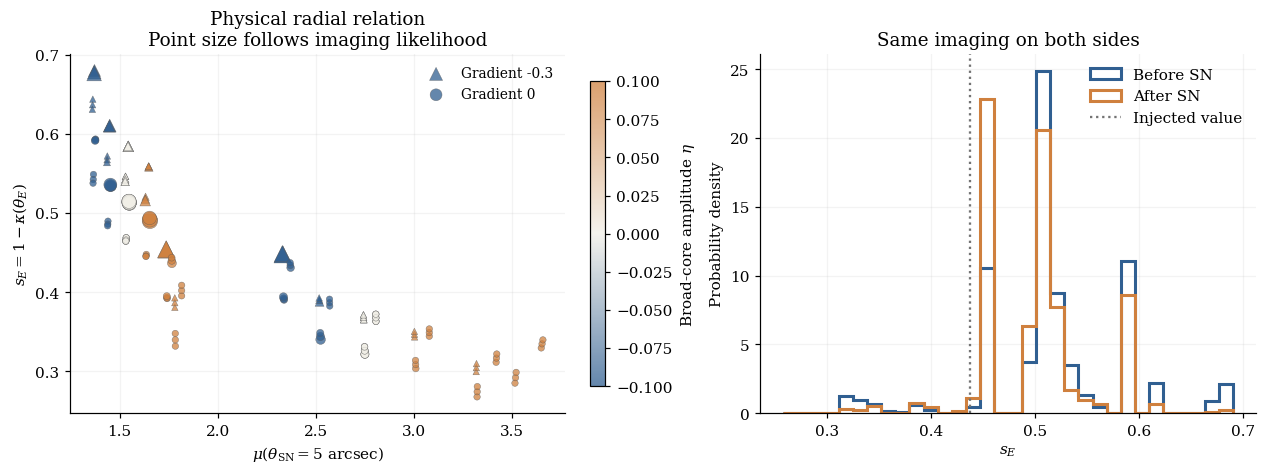

In [8]:
mu_outer, endpoint = np.exp(bank["lnmu"][0]), bank["s_E"][0]
imaging_weight = np.exp(log_imaging - np.max(log_imaging))
core_cmap = LinearSegmentedColormap.from_list("core", [blue, "#f1efe8", orange])
fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.2), constrained_layout=True)
for gradient, marker in [(-0.3, "^"), (0.0, "o")]:
    keep = admitted & np.isclose(grid.stellar_gradient, gradient)
    points = axes[0].scatter(
        mu_outer[keep], endpoint[keep], c=grid.eta_core[keep],
        cmap=core_cmap, vmin=-0.1, vmax=0.1, marker=marker,
        s=18 + 110 * imaging_weight[keep], alpha=0.75,
        edgecolor="0.35", linewidth=0.3, label=f"Gradient {gradient:g}",
    )
fig.colorbar(points, ax=axes[0], label=r"Broad-core amplitude $\eta$", shrink=0.85)
axes[0].set(xlabel=r"$\mu(\theta_{\rm SN}=5\ \mathrm{arcsec})$",
            ylabel=r"$s_E=1-\kappa(\theta_E)$",
            title="Physical radial relation\nPoint size follows imaging likelihood")
axes[0].legend(frameon=False, fontsize=9)
bins = np.linspace(endpoint[admitted].min() - 0.01, endpoint[admitted].max() + 0.01, 33)
for result, color, label in [(prior, blue, "Before SN"), (posterior, orange, "After SN")]:
    axes[1].hist(endpoint[admitted], bins=bins, weights=result.state_probability[admitted],
                 density=True, histtype="step", lw=2, color=color, label=label)
axes[1].axvline(endpoint[truth], color="0.45", ls=":", label="Injected value")
axes[1].set(xlabel=r"$s_E$", ylabel="Probability density", title="Same imaging on both sides")
axes[1].legend(frameon=False)
for ax in axes:
    ax.grid(alpha=0.15)
plt.show()

At similar outer magnification, core and stellar gradients can retain different inner endpoints. Brightness reweights this physical relation; the histogram shows its marginal on the discrete quadrature.

## 5. Average over possible SN measurements

A measurement can move probability into a broader part of the family and increase the posterior SD. The forecast averages posterior **variance** over the predictive brightness distribution:

$$\sigma_{\rm expected}=\sqrt{\int p(y\mid I,\mathrm{eligible})\,
\operatorname{Var}(s_E\mid y,I,\mathrm{eligible})\,dy}.$$

For a coherent model with converged integration, the law of total variance bounds this RMS by the prior SD.

In [9]:
residual_grid = np.linspace(-3.0, 1.0, 401)
forecast = radial.forecast(residual_grid)
posterior_sd = np.array([radial.posterior(y).standard_deviation for y in residual_grid])
widening = posterior_sd > prior.standard_deviation
widening_probability = trapezoid(forecast["predictive_density"] * widening, residual_grid)
print(f"Imaging-conditioned prior SD: {forecast['prior_sd']:.5f}")
print(f"Realised posterior SD:        {posterior.standard_deviation:.5f}")
print(f"Predictive RMS posterior SD:  {forecast['rms_posterior_sd']:.5f}")
print(f"Predictive integral:          {forecast['density_integral']:.8f}")
print(f"Probability of wider SD:      {widening_probability:.2%} (grid estimate)")

Imaging-conditioned prior SD: 0.06626
Realised posterior SD:        0.05142
Predictive RMS posterior SD:  0.05000
Predictive integral:          1.00000000
Probability of wider SD:      0.63% (grid estimate)


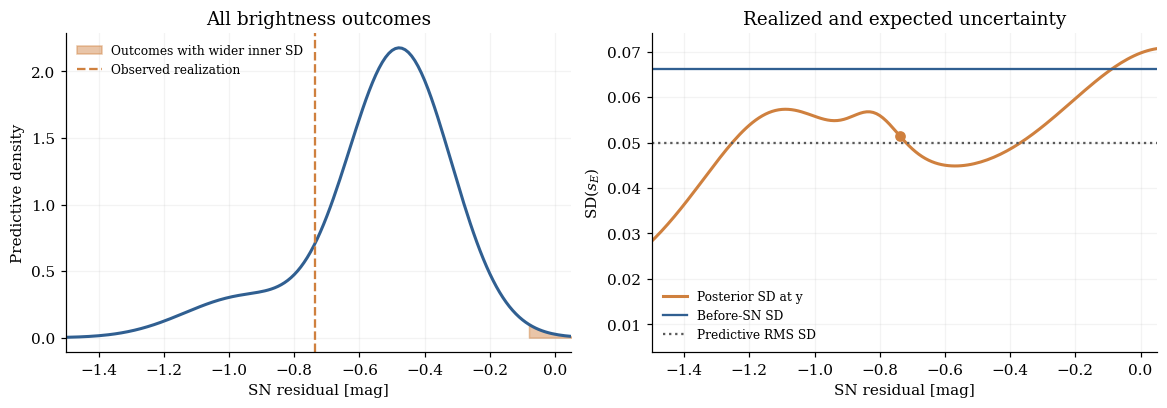

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), constrained_layout=True)
density = forecast["predictive_density"]
axes[0].plot(residual_grid, density, color=blue, lw=2)
axes[0].fill_between(residual_grid, 0, density, where=widening, color=orange,
                     alpha=0.45, label="Outcomes with wider inner SD")
axes[0].axvline(observed_residual, color=orange, ls="--", label="Observed realization")
axes[0].set(xlabel="SN residual [mag]", ylabel="Predictive density",
            title="All brightness outcomes")
axes[0].legend(frameon=False, fontsize=8)
axes[1].plot(residual_grid, posterior_sd, color=orange, lw=2, label="Posterior SD at y")
axes[1].axhline(prior.standard_deviation, color=blue, lw=1.5, label="Before-SN SD")
axes[1].axhline(forecast["rms_posterior_sd"], color="0.35", ls=":", label="Predictive RMS SD")
axes[1].scatter([observed_residual], [posterior.standard_deviation], color=orange, zorder=3)
axes[1].set(xlabel="SN residual [mag]", ylabel=r"SD($s_E$)", title="Realized and expected uncertainty")
axes[1].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.set_xlim(-1.5, 0.05)
    ax.grid(alpha=0.15)
plt.show()

## Exercise: change one assumption at a time

Try `sigma_sn=0.08`, `imaging_scale=2.0`, or `core_freedom="fixed_shape"`. Predict which reduces the expected SD and which changes the starting prior. Compare the prior SD, expected RMS SD and their ratio.

`fixed_shape` imposes $q=5$ and zero redistribution while retaining the $\eta$ axis. All scenarios keep the imaging data and SN radius fixed and average over their own predictive brightness distribution.

In [11]:
def compare_assumptions(sigma_sn=0.15, imaging_scale=1.0, core_freedom="full"):
    """Recompute the conditional forecast on the already-built physical bank."""
    choices = {"full": np.ones(len(grid), dtype=bool),
               "fixed_shape": np.isclose(grid.core_q, 5.0) & np.isclose(grid.compensation, 0.0)}
    keep = admitted & choices[core_freedom]
    logi = imaging_log_likelihood(
        bank["theta_e_arcsec"], bank["xi_E"], [observed_theta], [observed_xi],
        [sigma_theta * imaging_scale], [sigma_xi * imaging_scale],
    )[0]
    cal = ResponseCalibration.gaussian(
        [0.8, 1.6], np.linspace(-2.0, 0.5, 41), scatter_mag=sigma_sn,
        n_draws=1, rng=0,
    )
    transfer = RadialTransfer(endpoint, grid.base_probability,
        SourceLikelihood(sample, cal, nuisance), np.where(keep, logi, -np.inf))
    # Cover the physical shift range and >8 scatter widths, including nuisance.
    noise = np.sqrt(sigma_sn**2 + sample.extra_variance_mag2[0, keep, 0].max())
    shifts = sample.photon_shift_mag[0, keep, 0]
    ys = np.linspace(shifts.min() - 8 * noise - 0.1, shifts.max() + 8 * noise + 0.1, 401)
    return transfer.forecast(ys)

In [12]:
experiment = dict(sigma_sn=0.15, imaging_scale=1.0, core_freedom="full")
scenarios = [
    ("Your settings", experiment),
    ("SN: 0.08 mag", dict(sigma_sn=0.08)),
    ("Imaging errors x2", dict(imaging_scale=2.0)),
    ("Fixed core shape", dict(core_freedom="fixed_shape")),
]
print("Scenario             Prior SD   Expected SD   SD ratio")
for label, settings in scenarios:
    comparison = compare_assumptions(**settings)
    print(f"{label:20s} {comparison['prior_sd']:.5f}     "
          f"{comparison['rms_posterior_sd']:.5f}       "
          f"{comparison['rms_posterior_sd'] / comparison['prior_sd']:.3f}")

Scenario             Prior SD   Expected SD   SD ratio


Your settings        0.06626     0.05000       0.755


SN: 0.08 mag         0.06626     0.04393       0.663


Imaging errors x2    0.09293     0.05029       0.541


Fixed core shape     0.07436     0.05834       0.785


The fixed-core-shape restriction can raise the imaging-conditioned SD: removing states changes relative weights as well as support. Compare absolute SDs alongside their ratio.

## Numerical checks and interpretation

We check normalized state probabilities, unit predictive probability, and residual-grid convergence. For a new design, refine the mass-state axes and radial geometry grid as well.

Radial transfer depends on the family and its measure. Replace the Gaussian response or compressed imaging likelihood with calibrated inputs to extend the calculation, retaining the same conditioning before and after the SN update.

In [13]:
coarse = radial.forecast(residual_grid[::2])
for result in (prior, posterior):
    assert np.isclose(result.state_probability.sum(), 1.0)
    assert np.all(result.state_probability[~admitted] == 0)
assert np.isclose(forecast["density_integral"], 1.0, atol=1e-6)
assert forecast["rms_posterior_sd"] <= forecast["prior_sd"] + 1e-8
assert np.isclose(coarse["rms_posterior_sd"], forecast["rms_posterior_sd"], rtol=1e-4)
print(f"Checks passed. Runtime: {time.perf_counter() - started:.1f} s")

Checks passed. Runtime: 4.1 s


The [population-transfer notebook](03_population_transfer.ipynb) extends this pair calculation to independent strong lenses through a source–target population model.

See [the scientific model](../docs/science.rst), [the API](../docs/api.rst), and [the matched-profile example](../examples/radial_models.py), where distinct profiles share one outer brightness and retain different $s_E$.